In [1]:
import glob
import pandas as pd
import numpy as np
from matplotlib.colors import LinearSegmentedColormap


In [2]:
metadata_path = "/idiap/temp/group/genomics/AstroBF_fastq/RN22346/RN22346.xlsx"
metadata = pd.read_excel(metadata_path)
metadata['category'] = metadata["Sample Genotype"] + "_" + metadata["Sample Treatment"]

In [3]:
# Define a diverging colormap from pink to cyan
colors = ["navy", "#f7f7f7", "tomato"]  # Pink -> White -> Cyan
cmap = LinearSegmentedColormap.from_list("tomatoNavy", colors)

In [4]:
path_analysis_per_patient = "/idiap/temp/group/genomics/AstroBF_fastq/RN22346/230106_A01366_0335_BHJJHNDSX5/genes_preprocessing/BP_analysis_per_patient/GO"


In [5]:
csv_files = glob.glob(path_analysis_per_patient + '/*.csv')


In [6]:
samples_names = []
dataframes = []
increased = []
decreased = []
for file in csv_files:
    # Extract the sample name from the file path
    sample_name = file.split('/')[-1].split('.csv')[0]
    samples_names.append(sample_name)
    df = pd.read_csv(file)
    df.replace('NA', np.NaN)
    df.dropna(inplace=True)
    increase = df[(df[f'pvalue_{sample_name}'] < 0.05) & (df[f'gene_in_GO_{sample_name}'] == 'increase')].sort_values(f'pvalue_{sample_name}')
    increased.append(increase)
    decrease = df[(df[f'pvalue_{sample_name}'] < 0.05) & (df[f'gene_in_GO_{sample_name}'] == 'decrease')].sort_values(f'pvalue_{sample_name}')
    decreased.append(decrease)
    dataframes.append(df)


In [7]:
df_pvalues = pd.DataFrame()
for df, sample_name in zip(dataframes, samples_names):
    sign_ = (df[f'gene_in_GO_{sample_name}'] == 'increase').astype(int).replace(0, -1)
    pval_log = -np.log10(df[f'pvalue_{sample_name}'])
    df_pvalues[sample_name] = sign_*pval_log
df_pvalues.index = df['Description'].values

/idiap/temp/lfournier/miniconda3/envs/scRNApy-new/lib/python3.10/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/idiap/temp/lfournier/miniconda3/envs/scRNApy-new/lib/python3.10/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/idiap/temp/lfournier/miniconda3/envs/scRNApy-new/lib/python3.10/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/idiap/temp/lfournier/miniconda3/envs/scRNApy-new/lib/python3.10/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero encountered in log10
  result = getattr(ufunc, method)(*inputs, **kwargs)
/idiap/temp/lfournier/miniconda3/envs/scRNApy-new/lib/python3.10/site-packages/pandas/core/arraylike.py:402: RuntimeWarning: divide by zero enco

In [8]:
df_pvalues

,TAH5505A15,TAH5505A17,TAH5505A3,TAH5505A18,TAH5505A2,TAH5505A7,TAH5505A8,TAH5505A9,TAH5505A6,TAH5505A4,TAH5505A16,TAH5505A5,TAH5505A14,TAH5505A1,TAH5505A12,TAH5505A10,TAH5505A13,TAH5505A11
autophagosome assembly,0.098895,0.007416,0.178704,0.148941,0.105746,0.029132,0.142080,0.324105,0.565331,0.290885,-0.043053,0.179957,0.005944,0.026686,0.077870,0.145926,0.057171,0.132588
mitotic sister chromatid segregation,-0.263892,-0.167391,-0.373109,-0.285269,0.037716,0.072856,0.042158,-0.237369,-0.718842,-0.736445,-0.175386,-0.549589,0.006196,0.029559,-0.444758,-0.575146,-0.366705,-0.488297
DNA damage checkpoint signaling,-0.130228,0.017124,-0.242072,-0.172428,-0.068656,-0.145332,-0.091118,-0.215640,-0.326914,-0.452910,-0.196045,0.002021,0.018871,-0.137775,-0.135799,-0.273380,-0.289046,-0.155763
regulation of cyclin-dependent protein serine/threonine kinase activity,5.173651,0.487336,2.618208,2.984400,1.523746,4.943540,3.312955,2.104387,0.790721,1.449807,1.569344,0.475747,1.087095,5.453638,2.714034,2.198821,2.461253,1.343622
G1/S transition of mitotic cell cycle,0.522926,0.177662,0.438696,1.327206,0.799866,0.866538,3.202870,1.342249,1.628319,0.324125,0.484616,0.333337,0.491753,0.695200,0.502302,-0.053596,0.218518,0.064840
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ubiquitin-specific protease binding,1.566389,0.324514,1.682606,2.227661,2.894753,1.206849,1.795807,2.019472,1.473164,1.024367,1.078211,0.955698,1.155180,0.891258,0.703056,1.159742,1.008045,0.610646
ubiquitin ligase-substrate adaptor activity,-0.170928,-0.106687,-0.154952,-0.190970,-0.136393,-0.147953,-0.245930,-0.228531,-0.194468,-0.055498,-0.111702,-0.001196,-0.242865,-0.170591,-0.073292,-0.035931,-0.099738,-0.096639
protein tyrosine kinase binding,1.262805,0.643019,0.516088,1.168967,1.381162,2.029301,2.958486,0.891268,1.232557,0.657877,1.032230,1.489423,0.689872,2.220809,0.753572,0.483289,0.810340,0.789956
sequence-specific double-stranded DNA binding,-1.876172,-2.316266,-1.938318,-1.971006,-2.174231,-2.757423,-1.728518,-2.263644,-2.320627,-2.620598,-2.487776,-1.400607,-1.796873,-2.144441,-1.681878,-1.381027,-2.448458,-1.501529


In [9]:
df_pvalues

,TAH5505A15,TAH5505A17,TAH5505A3,TAH5505A18,TAH5505A2,TAH5505A7,TAH5505A8,TAH5505A9,TAH5505A6,TAH5505A4,TAH5505A16,TAH5505A5,TAH5505A14,TAH5505A1,TAH5505A12,TAH5505A10,TAH5505A13,TAH5505A11
autophagosome assembly,0.098895,0.007416,0.178704,0.148941,0.105746,0.029132,0.142080,0.324105,0.565331,0.290885,-0.043053,0.179957,0.005944,0.026686,0.077870,0.145926,0.057171,0.132588
mitotic sister chromatid segregation,-0.263892,-0.167391,-0.373109,-0.285269,0.037716,0.072856,0.042158,-0.237369,-0.718842,-0.736445,-0.175386,-0.549589,0.006196,0.029559,-0.444758,-0.575146,-0.366705,-0.488297
DNA damage checkpoint signaling,-0.130228,0.017124,-0.242072,-0.172428,-0.068656,-0.145332,-0.091118,-0.215640,-0.326914,-0.452910,-0.196045,0.002021,0.018871,-0.137775,-0.135799,-0.273380,-0.289046,-0.155763
regulation of cyclin-dependent protein serine/threonine kinase activity,5.173651,0.487336,2.618208,2.984400,1.523746,4.943540,3.312955,2.104387,0.790721,1.449807,1.569344,0.475747,1.087095,5.453638,2.714034,2.198821,2.461253,1.343622
G1/S transition of mitotic cell cycle,0.522926,0.177662,0.438696,1.327206,0.799866,0.866538,3.202870,1.342249,1.628319,0.324125,0.484616,0.333337,0.491753,0.695200,0.502302,-0.053596,0.218518,0.064840
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ubiquitin-specific protease binding,1.566389,0.324514,1.682606,2.227661,2.894753,1.206849,1.795807,2.019472,1.473164,1.024367,1.078211,0.955698,1.155180,0.891258,0.703056,1.159742,1.008045,0.610646
ubiquitin ligase-substrate adaptor activity,-0.170928,-0.106687,-0.154952,-0.190970,-0.136393,-0.147953,-0.245930,-0.228531,-0.194468,-0.055498,-0.111702,-0.001196,-0.242865,-0.170591,-0.073292,-0.035931,-0.099738,-0.096639
protein tyrosine kinase binding,1.262805,0.643019,0.516088,1.168967,1.381162,2.029301,2.958486,0.891268,1.232557,0.657877,1.032230,1.489423,0.689872,2.220809,0.753572,0.483289,0.810340,0.789956
sequence-specific double-stranded DNA binding,-1.876172,-2.316266,-1.938318,-1.971006,-2.174231,-2.757423,-1.728518,-2.263644,-2.320627,-2.620598,-2.487776,-1.400607,-1.796873,-2.144441,-1.681878,-1.381027,-2.448458,-1.501529


In [10]:
treatments = {'ctrl2_basal': ['TAH5505A1'], 
              'glib_basal': ['TAH5505A10'], 
              'glib_A1 low': ['TAH5505A11'], 
              'glib_A1 high': ['TAH5505A12'], 
              'cbie_basal': ['TAH5505A13'], 
              'cbie_A1 low': ['TAH5505A14'], 
              'cbie_A1 high': ['TAH5505A15'], 
              'ctrl6_basal': ['TAH5505A16'], 
              'ctrl6_A1 low': ['TAH5505A17'], 
              'ctrl6_A1 high': ['TAH5505A18'], 
              'ctrl2_A1 low': ['TAH5505A2'], 
              'ctrl2_A1 high': ['TAH5505A3'], 
              'ctrl3_basal': ['TAH5505A4'], 
              'ctrl3_A1 low': ['TAH5505A5'], 
              'ctrl3_A1 high': ['TAH5505A6'], 
              'glia_basal': ['TAH5505A7'], 
              'glia_A1 low': ['TAH5505A8'], 
              'glia_A1 high': ['TAH5505A9']}

treatments_cell_lines = {'ctrl_basal': ['TAH5505A1', 'TAH5505A16', 'TAH5505A4'],
 'ctrl_A1 low': ['TAH5505A17', 'TAH5505A2', 'TAH5505A5'],
 'ctrl_A1 high': ['TAH5505A18', 'TAH5505A3', 'TAH5505A6'],
 'vcp_basal': ['TAH5505A10', 'TAH5505A13', 'TAH5505A7'],
 'vcp_A1 low': ['TAH5505A11', 'TAH5505A14', 'TAH5505A8'],
 'vcp_A1 high': ['TAH5505A12', 'TAH5505A15', 'TAH5505A9']}

palette_genotype = {"ctrl_basal": 'palegreen', "ctrl_A1 low": "limegreen", "ctrl_A1 high": "forestgreen", "vcp_basal": "pink", "vcp_A1 low": "hotpink", "vcp_A1 high": "deeppink" }
palette_treatments = {"ctrl_basal": 'dimgray', "ctrl_A1 low": "deepskyblue", "ctrl_A1 high": "darkorange", "vcp_basal": "dimgray", "vcp_A1 low": "deepskyblue", "vcp_A1 high": "darkorange" }

In [11]:
treatments_cell_lines

{'ctrl_basal': ['TAH5505A1', 'TAH5505A16', 'TAH5505A4'],
 'ctrl_A1 low': ['TAH5505A17', 'TAH5505A2', 'TAH5505A5'],
 'ctrl_A1 high': ['TAH5505A18', 'TAH5505A3', 'TAH5505A6'],
 'vcp_basal': ['TAH5505A10', 'TAH5505A13', 'TAH5505A7'],
 'vcp_A1 low': ['TAH5505A11', 'TAH5505A14', 'TAH5505A8'],
 'vcp_A1 high': ['TAH5505A12', 'TAH5505A15', 'TAH5505A9']}

In [12]:
ordered_treatments_basal = []
for key, samples in treatments_cell_lines.items():
    if "basal" in key:
        ordered_treatments_basal.extend(samples)

In [13]:
df_pvalues = df_pvalues[ordered_treatments_basal]

In [14]:
# More robust cleaning of infinite and NaN values
print("Data shape before cleaning:", df_pvalues.shape)
print("Number of infinite values:", np.isinf(df_pvalues).sum().sum())
print("Number of NaN values:", df_pvalues.isna().sum().sum())

# Replace infinite values with the maximum finite value
max_finite_value = df_pvalues.replace([np.inf, -np.inf], np.nan).max().max()
df_pvalues = df_pvalues.replace([np.inf, -np.inf], max_finite_value)

# Fill any remaining NaN values with 0
df_pvalues = df_pvalues.fillna(0)

print("After cleaning:")
print("Number of infinite values:", np.isinf(df_pvalues).sum().sum())
print("Number of NaN values:", df_pvalues.isna().sum().sum())
print("Data range:", df_pvalues.min().min(), "to", df_pvalues.max().max())

Data shape before cleaning: (2112, 6)
Number of infinite values: 479
Number of NaN values: 0
After cleaning:
Number of infinite values: 0
Number of NaN values: 0
Data range: -6.110124911683689 to 15.653559774527022


In [15]:
-np.log(0.05)

2.995732273553991

In [16]:
df_filtered = df_pvalues[(df_pvalues.abs() > -np.log(0.05)).any(axis=1)]   


Before additional cleaning:
Data shape: (551, 6)
Data range: -6.110124911683689 to 15.653559774527022
Rows with zero variance: 0
Columns with zero variance: 0
After cleaning:
Data shape: (551, 6)
Data range: -6.110124911683689 to 15.653559774527022
Final check - any infinite or NaN values: False


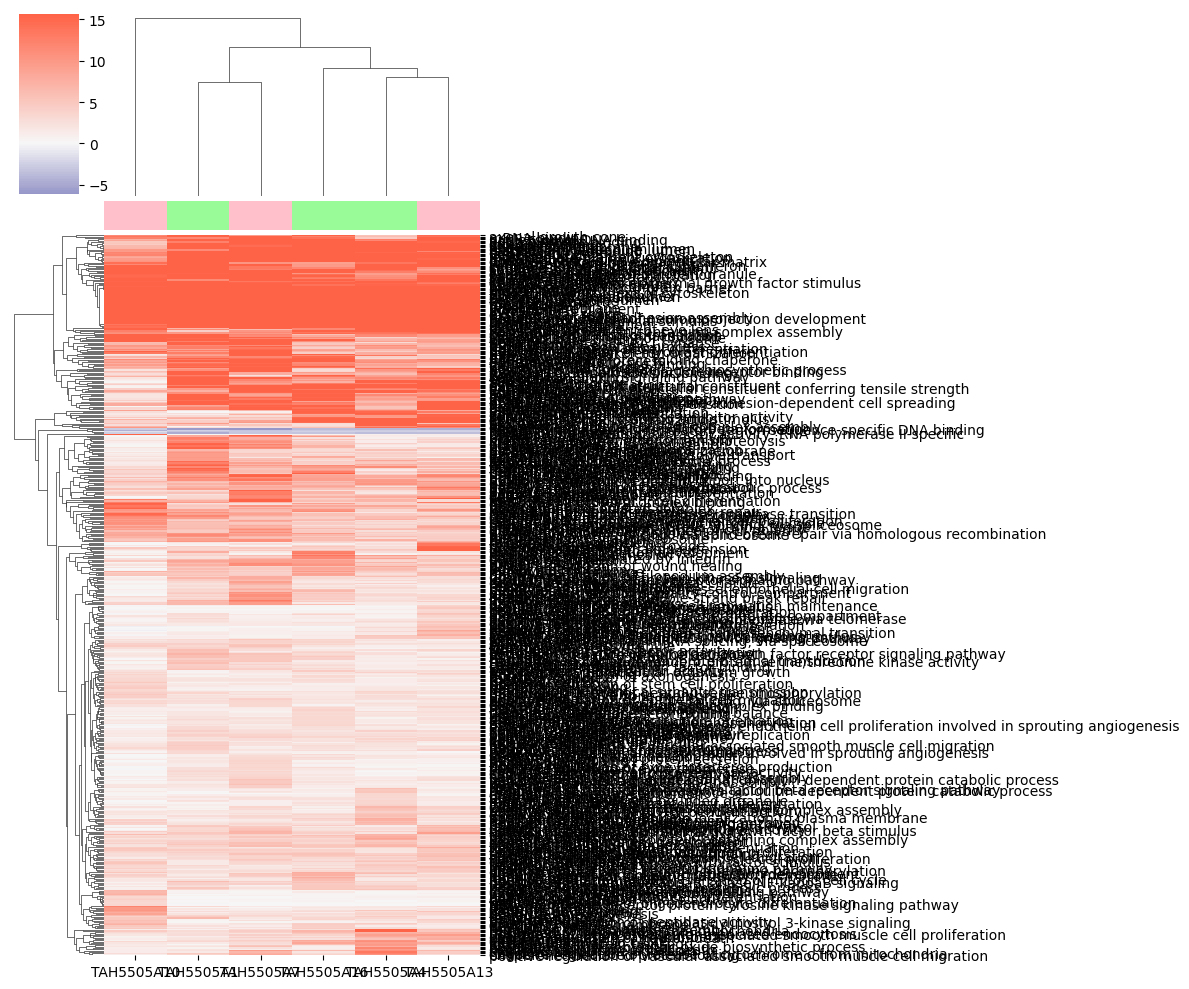

Success with standard scaling!


In [17]:
import seaborn as sns
import matplotlib.pyplot as plt

# Create the color mapping for columns
col_colors = []
for treatment, samples in treatments_cell_lines.items():
    for sample in samples:
        if sample in df_filtered.columns:
            col_colors.append(palette_genotype[treatment])

# Additional data cleaning for clustering
print("Before additional cleaning:")
print("Data shape:", df_filtered.shape)
print("Data range:", df_filtered.min().min(), "to", df_filtered.max().max())

# Remove rows with zero variance (all identical values)
row_variance = df_filtered.var(axis=1)
print(f"Rows with zero variance: {(row_variance == 0).sum()}")
df_clean = df_filtered[row_variance > 0]

# Remove columns with zero variance  
col_variance = df_clean.var(axis=0)
print(f"Columns with zero variance: {(col_variance == 0).sum()}")
df_clean = df_clean.loc[:, col_variance > 0]

# Update col_colors to match remaining columns
col_colors_clean = []
for treatment, samples in treatments_cell_lines.items():
    for sample in samples:
        if sample in df_clean.columns:
            col_colors_clean.append(palette_genotype[treatment])

print("After cleaning:")
print("Data shape:", df_clean.shape)
print("Data range:", df_clean.min().min(), "to", df_clean.max().max())

# Verify that we have finite values for clustering
print("Final check - any infinite or NaN values:", 
      np.isinf(df_clean).any().any() or df_clean.isna().any().any())

# Create clustermap with multiple fallback options

# First try with standard scaling
g = sns.clustermap(df_clean, 
                    col_colors=col_colors_clean,
                    col_cluster=True, 
                    row_cluster=True, 
                    yticklabels=True,
                    cmap=cmap,
                    center=0,
                    figsize=(12, 10))
plt.show()
print("Success with standard scaling!")


After cleaning:
Data shape: (551, 6)
Data range: -6.110124911683689 to 15.653559774527022
Final check - any infinite or NaN values: False


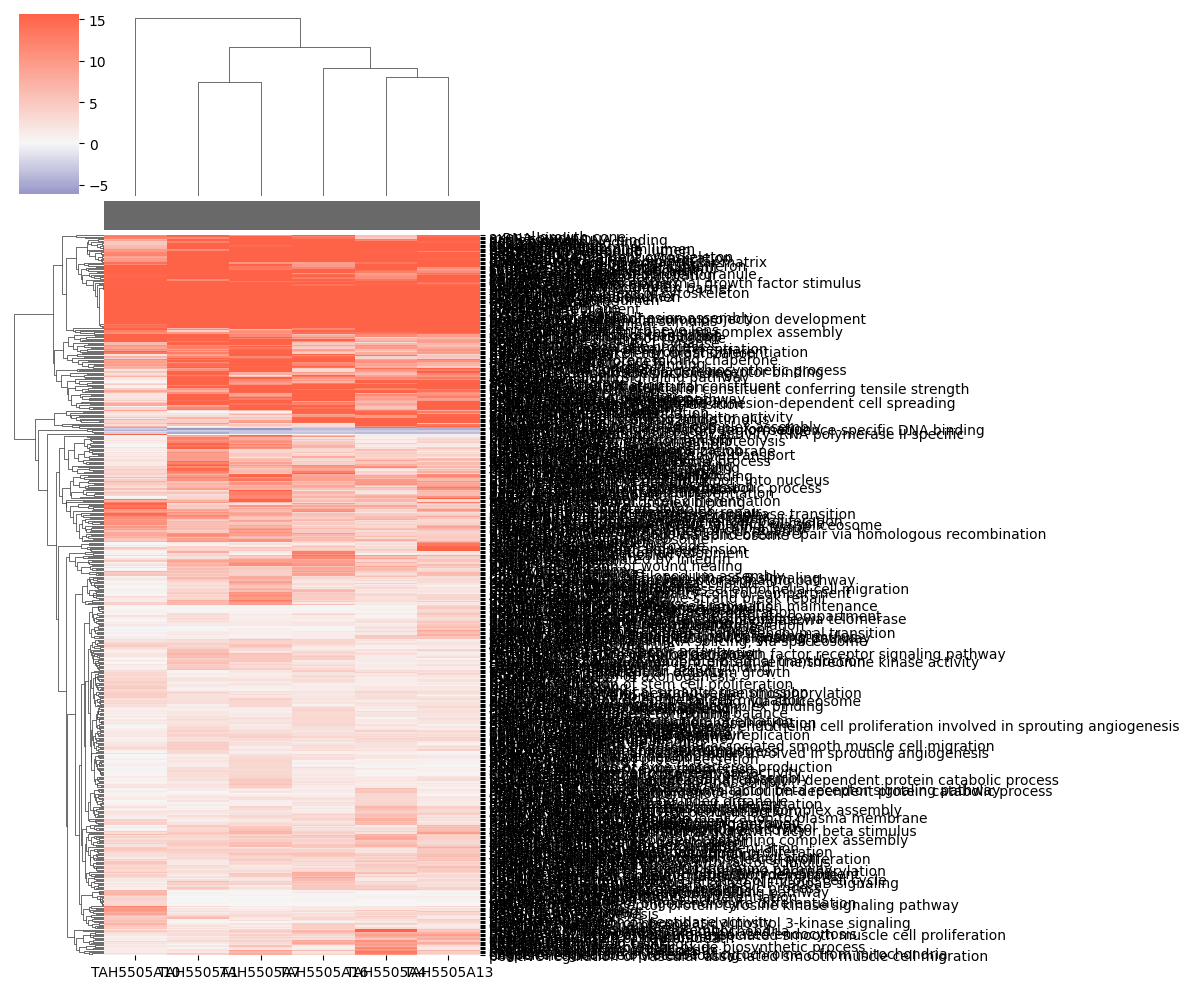

Success with standard scaling!


In [18]:
# Update col_colors to match remaining columns
col_colors_clean = []
for treatment, samples in treatments_cell_lines.items():
    for sample in samples:
        if sample in df_clean.columns:
            col_colors_clean.append(palette_treatments[treatment])

print("After cleaning:")
print("Data shape:", df_clean.shape)
print("Data range:", df_clean.min().min(), "to", df_clean.max().max())

# Verify that we have finite values for clustering
print("Final check - any infinite or NaN values:", 
      np.isinf(df_clean).any().any() or df_clean.isna().any().any())

# Create clustermap with multiple fallback options

# First try with standard scaling
g = sns.clustermap(df_clean, 
                    col_colors=col_colors_clean,
                    col_cluster=True, 
                    row_cluster=True, 
                    yticklabels=True, 
                    cmap=cmap,
                    center=0, 
                    figsize=(12, 10))
plt.show()
print("Success with standard scaling!")

In [21]:
from melapa.OmicsDataset import OmicsDataset

pvalues_dataset = OmicsDataset(df=df_pvalues, treatments=treatments, nb_comp=6, 
                          df_log=df_pvalues)

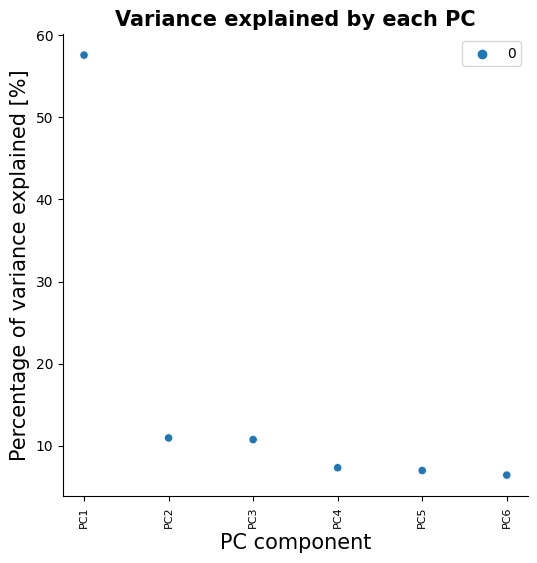

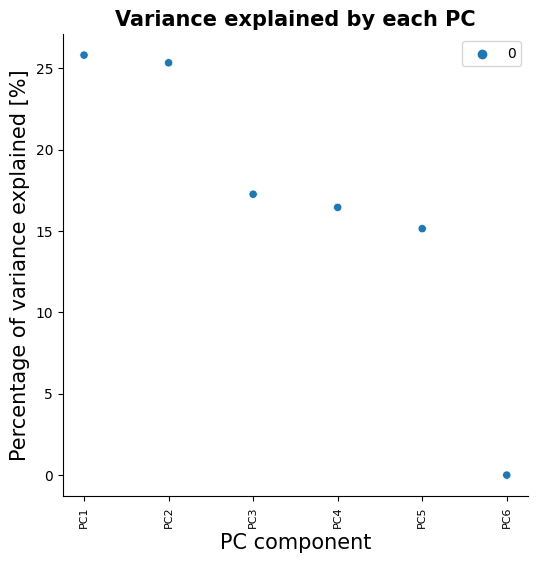

In [22]:
pvalues_dataset.perform_svd_analysis(top_n=6)

In [23]:
pvalues_dataset.pca = pvalues_dataset.pca.merge(metadata[['category', 'Sample Treatment', 'Sample Genotype', 'limsid']], left_index=True, right_on='limsid')

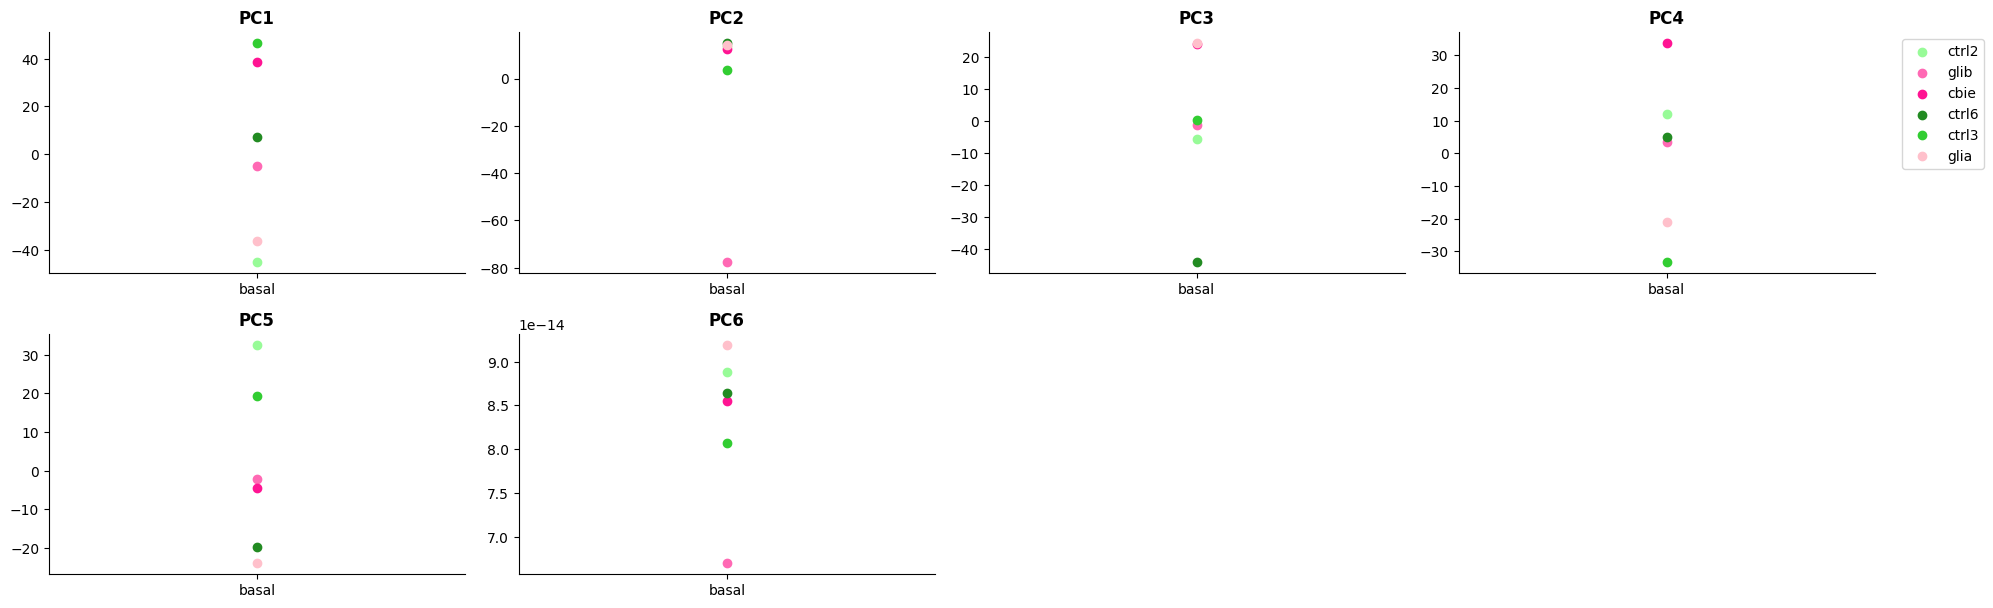

In [26]:
palette_genotype = {"ctrl2": 'palegreen', "ctrl3": "limegreen", "ctrl6": "forestgreen", "glia": "pink", "glib": "hotpink", "cbie": "deeppink" }
plt.figure(figsize=(20, 15))
for pc in range(6):
    plt.subplot(5, 4, pc+1)
    for genotype in pvalues_dataset.pca['Sample Genotype'].unique():
        subset = pvalues_dataset.pca[pvalues_dataset.pca['Sample Genotype'] == genotype]
        # subset.index = [idx.split('_')[1] for idx in subset.index]
        subset.set_index("Sample Treatment", inplace=True)
        subset = subset.loc[["basal"]]
        plt.scatter(x=subset.index, y=subset[f'PC{pc+1}'], label=genotype, color=palette_genotype[genotype])
        plt.plot(subset.index, subset[f'PC{pc+1}'], color=palette_genotype[genotype])
    if pc == 3:
        plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    sns.despine()
    plt.title(f"PC{pc+1}", weight='bold')
plt.tight_layout()

In [27]:
pvalues_dataset.pca['mutation'] = ["ctrl" if "ctrl" in genotype else "vcp" for genotype in pvalues_dataset.pca['Sample Genotype']]

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=9.17e-01
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=4.56e-01
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=1.33e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=6.40e-01
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=3.18e-01
p-value annotation legend:
      ns: p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

ctrl vs. vcp: P=6.69e-01


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


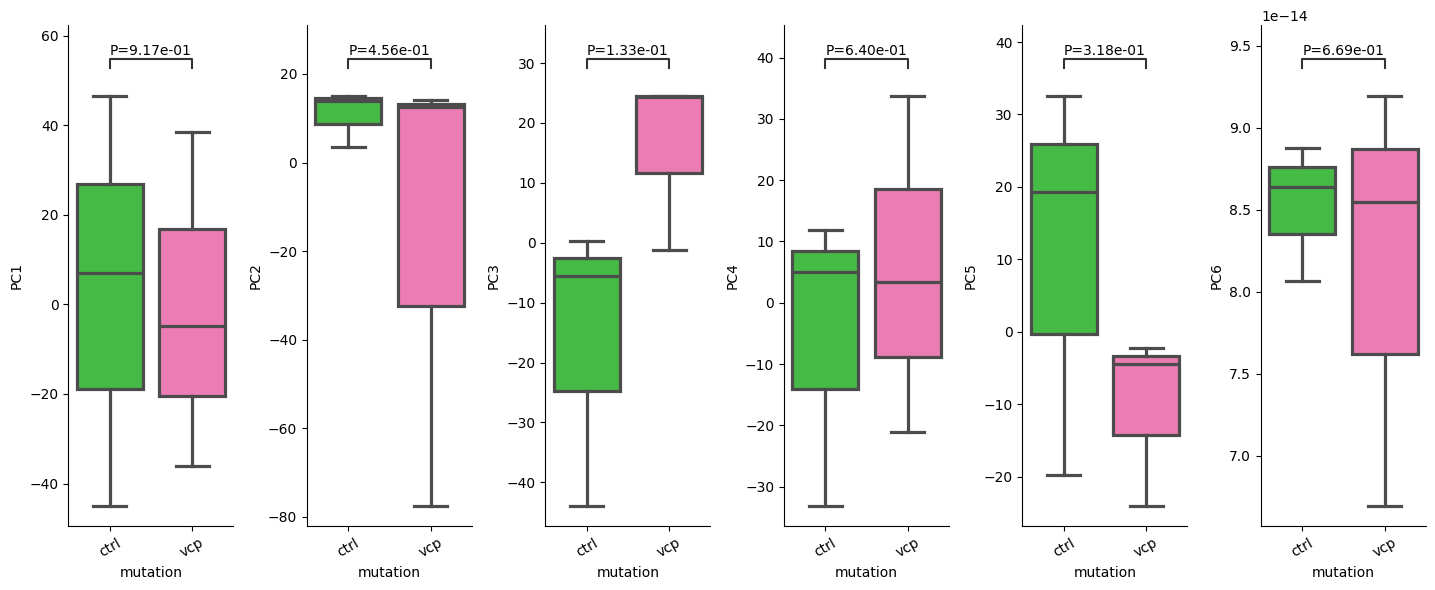

In [28]:
from melapa.helper_plot import boxplot_pca_significance

boxplot_pca_significance(pvalues_dataset.pca, treatment_col='mutation', fontsize=10, palette={'ctrl': 'limegreen', 'vcp': 'hotpink'})

In [34]:
pvalues_dataset.pca['treatment'] = pvalues_dataset.pca['Sample Treatment']
pvalues_dataset.pca['genotype'] = pvalues_dataset.pca['Sample Genotype']

In [32]:
pvalues_dataset.pca

,PC1,PC2,PC3,PC4,PC5,PC6,treatment,category,Sample Treatment,Sample Genotype,limsid,mutation
0,-44.958252,13.891146,-5.508548,11.923325,32.610037,8.878267e-14,basal,ctrl2_basal,basal,ctrl2,TAH5505A1,ctrl
1,-4.937887,-77.470313,-1.138109,3.314910,-2.233689,6.694919e-14,basal,glib_basal,basal,glib,TAH5505A10,vcp
4,38.369780,12.581285,24.273520,33.806773,-4.433560,8.549260e-14,basal,cbie_basal,basal,cbie,TAH5505A13,vcp
7,7.041878,15.114266,-43.898805,5.093262,-19.800680,8.638568e-14,basal,ctrl6_basal,basal,ctrl6,TAH5505A16,ctrl
33,46.602087,3.460270,0.281014,-33.117151,19.235690,8.065986e-14,basal,ctrl3_basal,basal,ctrl3,TAH5505A4,ctrl
39,-36.163022,14.059880,24.572337,-21.091276,-24.007560,9.195765e-14,basal,glia_basal,basal,glia,TAH5505A7,vcp


In [39]:
projection_PC3 = pvalues_dataset.Vt_w1[2]
indexes_top = np.argsort(projection_PC3)[-50:]
indexes_bottom = np.argsort(projection_PC3)[:50]

top_highest_PC3 = list(pvalues_dataset.df.reset_index().iloc[indexes_top]['index'].values)
top_lowest_PC3 = list(pvalues_dataset.df.reset_index().iloc[indexes_bottom]['index'].values)

In [40]:
top_proj40 = pd.concat([
              pvalues_dataset.X_without_PC1.T.loc[top_highest_PC3],
              pvalues_dataset.X_without_PC1.T.loc[top_lowest_PC3],
              ]).drop_duplicates(keep='first')


top_proj40 = top_proj40[ordered_treatments_basal]

In [41]:
palette_genotype = {"ctrl_basal": 'palegreen', "ctrl_A1 low": "limegreen", "ctrl_A1 high": "forestgreen", "vcp_basal": "pink", "vcp_A1 low": "hotpink", "vcp_A1 high": "deeppink" }

palette_genotype = {"ctrl_basal": 'limegreen', "ctrl_A1 low": "limegreen", "ctrl_A1 high": "limegreen", "vcp_basal": "hotpink", "vcp_A1 low": "hotpink", "vcp_A1 high": "hotpink" }



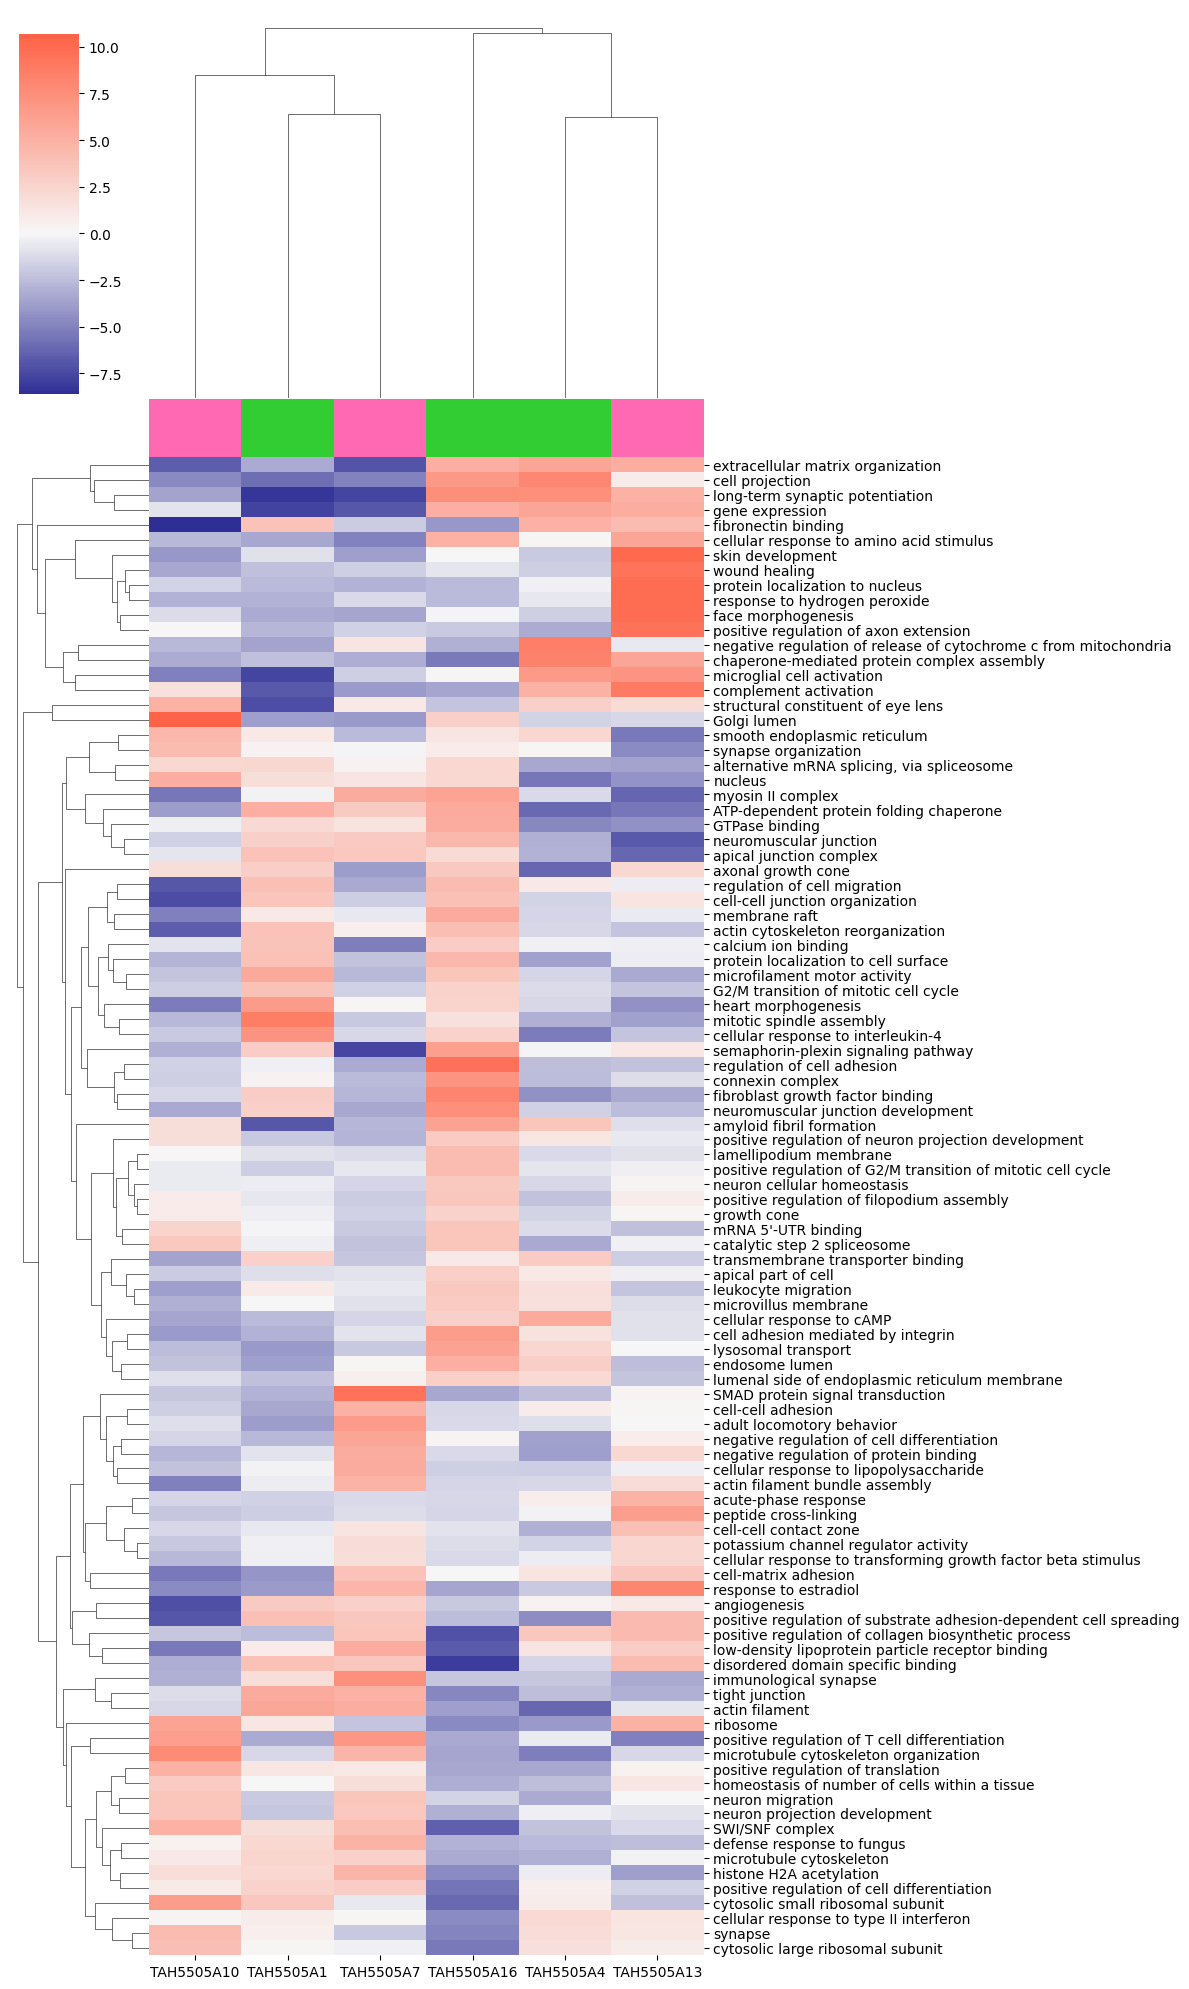

Success with standard scaling!


In [42]:

# Update col_colors to match remaining columns
col_colors_clean = []
for treatment, samples in treatments_cell_lines.items():
    for sample in samples:
        if sample in top_proj40.columns:
            col_colors_clean.append(palette_genotype[treatment])
            
            
# First try with standard scaling
g = sns.clustermap(top_proj40, 
                    col_colors=col_colors_clean,
                    col_cluster=True, 
                    row_cluster=True, 
                    yticklabels=True, 
                    cmap=cmap,
                    center=0,                     figsize=(12, 20))
plt.show()
print("Success with standard scaling!")